# Recebimentos e parcelamento

**Tabela:** `fact_recebimentos` · **Grão:** Evento de recebimento (parcela).

Análise descritiva do snapshot CSV. Figuras em azul, sem grade de fundo; PNG e SVG são exportados em `ml/reports/figures/eda/`. As relações usam as chaves vinculadas às versões do cadastro.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml").is_dir() and (p / "sql").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ml.data import load_tables
from ml.plotting import configure_style, style_table, save_figure
from ml.config import REPORTS, ARTIFACTS
get_ipython().run_line_magic("matplotlib", "inline")
configure_style()
pd.set_option("display.max_columns", 40)


In [2]:
from ml.eda import overview, profile, analyze_table
tables = load_tables()
df = tables["fact_recebimentos"]
overview("fact_recebimentos", df)


## Estrutura e qualidade

Confira nulos e cardinalidade. `vigencia_fim` vazia é esperada em versões atuais; prazo médio vazio é esperado em parceiros sem histórico. Colunas constantes não devem ser interpretadas como evidência preditiva.

In [3]:
display(style_table(profile(df)))

Coluna,Tipo,Nulos,Nulos (%),Distintos
id_recebimento_natural,object,0,0.000000,18681
id_transacao_natural,object,0,0.000000,16625
data,datetime64[ns],0,0.000000,765
valor_recebido,float64,0,0.000000,18290
metodo_recebimento,object,0,0.000000,6
comprovante,object,0,0.000000,18681
source_system,object,0,0.000000,1
recebimento_sk,int64,0,0.000000,18681
transacao_sk,int64,0,0.000000,16625
moeda_sk,int64,0,0.000000,1


## Distribuições e comportamento

As unidades e regras de agregação aparecem em cada figura. Valores financeiros descrevem o dataset sintético em BRL.

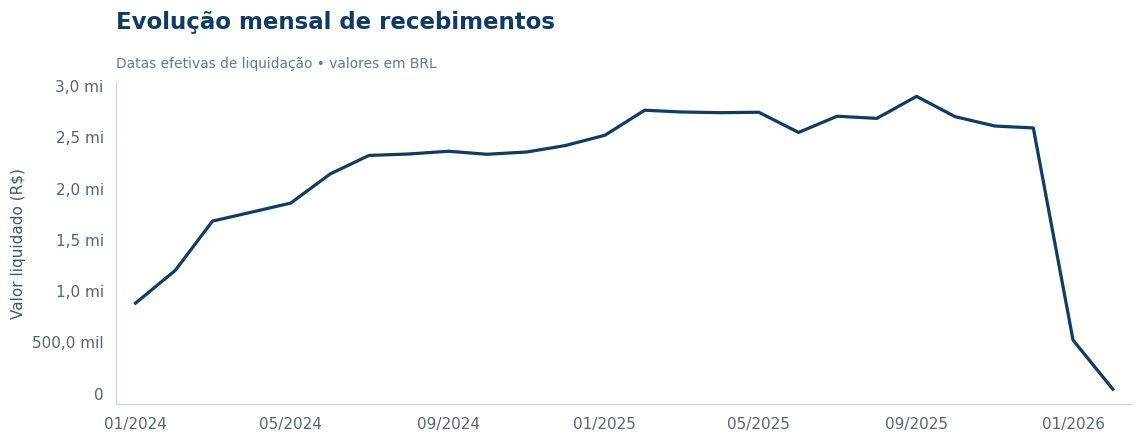

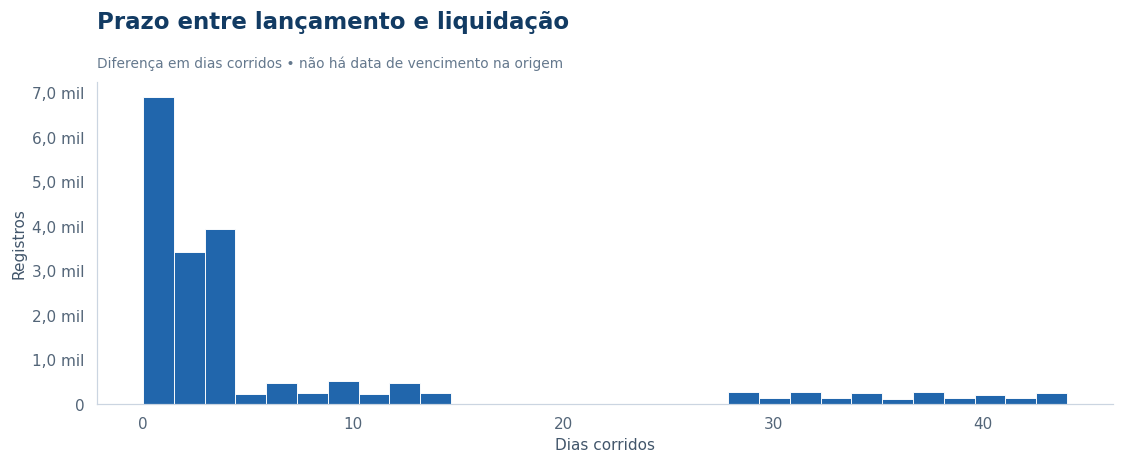

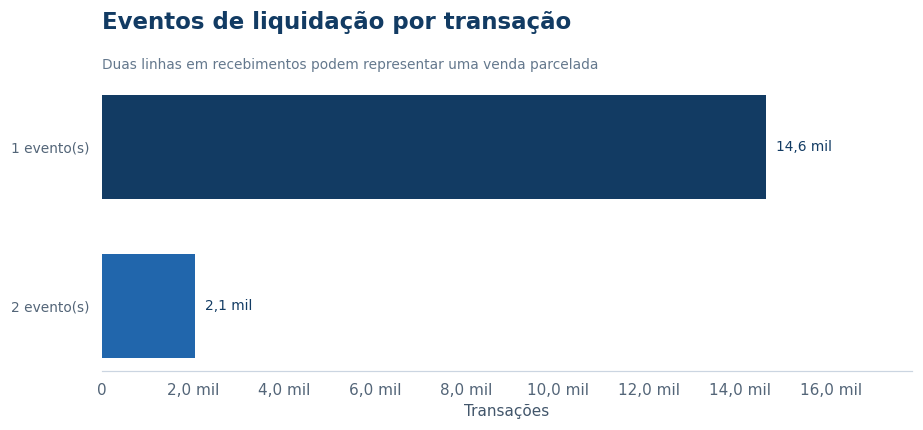

In [4]:
figures, notes = analyze_table("fact_recebimentos", tables)
for figure in figures:
    display(figure)
    plt.close(figure)


## Conclusões da tabela

In [5]:
display(Markdown("\n\n".join("- " + note for note in notes)))

- **18,681 eventos** para **16,625 transações**; prazo mediano de **2 dias**.

- Nas operações PAGO, diferença máxima entre a soma liquidada e o líquido: **R$ 0.00**.

- **2,056 transações** têm duas parcelas; sua soma foi conciliada pelo ETL. Pagamentos futuros não entram no modelo no instante da transação.

## Relação com o modelo

A detecção usa somente atributos conhecidos no lançamento e históricos de dias anteriores. Esta análise é descritiva; tabelas de liquidação, saldos, RH e ratings completos não entram automaticamente no treinamento.